# Lab 04.3 — CNN 1D với **TensorFlow / Keras**

Cài đặt thứ ba của *cùng* mô hình. Khác biệt đáng chú ý nhất so với PyTorch:

* Keras dùng layout **channels-last**: `(N, L, C)` thay vì `(N, C, L)`;
* huấn luyện gọn trong `model.fit()`, nhưng ta cũng viết lại **một vòng lặp
  `GradientTape` thủ công** để thấy rõ tương ứng với notebook 01;
* gradient do `tf.GradientTape` ghi lại thay vì autograd.

| | NumPy | PyTorch | TensorFlow |
|---|---|---|---|
| Convolution | `conv1d()` tự viết | `nn.Conv1d` | `layers.Conv1D` |
| Pooling | `maxpool1d()` tự viết | `nn.MaxPool1d` | `layers.MaxPooling1D` |
| Gradient | công thức thủ công | autograd | `GradientTape` |
| Vòng lặp | tự viết | tự viết | `fit()` hoặc tự viết |

> **Kernel:** notebook này cần kernel *Python (TF 2.21)* — môi trường ảo
> `.venv-tf` đã cài TensorFlow 2.21 (TF chưa hỗ trợ Python 3.14 của kernel mặc định).

In [1]:
import os
import sys
import time
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")   # bo log INFO cua TF

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd()))
import lab04_data as L4

tf.random.set_seed(42)
np.random.seed(42)
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "khong co (chay CPU)")

TensorFlow: 2.21.0 | Keras: 3.15.1


GPU: khong co (chay CPU)


## 1. Kiểm chứng lại phép convolution

Nạp kernel $k = [0.5, -1, 0.5]$ vào `layers.Conv1D` rồi so sánh với
convolution viết tay. Lưu ý hình dạng weight của Keras là
`(kernel_size, in_channels, out_channels)` — khác PyTorch `(out, in, kernel)`,
nhưng phép toán thì không đổi.

In [2]:
def conv1d_naive(x, k, b=0.0):
    m = len(k)
    return np.array([sum(k[j] * x[i + j] for j in range(m)) + b
                     for i in range(len(x) - m + 1)])


x = np.array([2.0, 1.0, 3.0, 4.0, 2.0], dtype=np.float32)
k = np.array([0.5, -1.0, 0.5], dtype=np.float32)

conv = layers.Conv1D(filters=1, kernel_size=3, use_bias=True)
conv.build((None, 5, 1))
conv.set_weights([k.reshape(3, 1, 1), np.zeros(1, dtype=np.float32)])

z_tf = conv(x.reshape(1, 5, 1)).numpy().ravel()
print("NumPy thu cong   :", conv1d_naive(x, k))
print("layers.Conv1D    :", z_tf)
print("ReLU(Conv1D)     :", tf.nn.relu(z_tf).numpy())
assert np.allclose(conv1d_naive(x, k), z_tf, atol=1e-5)
print("\n=> Cai dat thu ba, van CUNG mot ket qua.")

NumPy thu cong   : [ 1.5 -0.5 -1.5]
layers.Conv1D    : [ 1.5 -0.5 -1.5]
ReLU(Conv1D)     : [1.5 0.  0. ]

=> Cai dat thu ba, van CUNG mot ket qua.


## 2. Mô hình Keras

Dùng cùng khởi tạo như hai notebook trước (He normal cho conv/dense,
$\mathcal{N}(0, 0.05)$ cho embedding) để phép so sánh vẫn là *controlled experiment*.

In [3]:
HE = keras.initializers.HeNormal(seed=42)
EMB_INIT = keras.initializers.RandomNormal(mean=0.0, stddev=0.05, seed=42)


def build_tabular_cnn(n_features, hidden=16, dense=None, out_activation=None):
    """Conv1D -> ReLU -> Conv1D -> ReLU -> MaxPool -> Flatten -> Dense(...) -> output."""
    model = keras.Sequential(name="tabular_cnn")
    model.add(keras.Input(shape=(n_features, 1)))            # channels-last!
    model.add(layers.Conv1D(hidden, 3, activation="relu", kernel_initializer=HE))
    model.add(layers.Conv1D(hidden, 3, activation="relu", kernel_initializer=HE))
    model.add(layers.MaxPooling1D(2))
    model.add(layers.Flatten())
    if dense:
        model.add(layers.Dense(dense, activation="relu", kernel_initializer=HE))
    model.add(layers.Dense(1, activation=out_activation, kernel_initializer=HE))
    return model


def build_text_cnn(vocab_size, max_len, emb=32, ch=64, n_classes=3, p_drop=0.3):
    model = keras.Sequential(name="text_cnn")
    model.add(keras.Input(shape=(max_len,), dtype="int32"))
    model.add(layers.Embedding(vocab_size, emb, embeddings_initializer=EMB_INIT))
    model.add(layers.Conv1D(ch, 3, activation="relu", kernel_initializer=HE))
    model.add(layers.MaxPooling1D(2))
    model.add(layers.Conv1D(ch, 3, activation="relu", kernel_initializer=HE))
    model.add(layers.GlobalMaxPooling1D())
    model.add(layers.Dropout(p_drop, seed=42))
    model.add(layers.Dense(n_classes, activation="softmax", kernel_initializer=HE))
    return model

## 3. Diabetes — phân lớp nhị phân với `fit()`

Output `sigmoid` và loss `binary_crossentropy`.

In [4]:
dia = L4.load_diabetes()
Xtr = dia["X_train"][:, :, None].astype("float32")        # (N, 8, 1)
Xte = dia["X_test"][:, :, None].astype("float32")
ytr, yte = dia["y_train"].astype("float32"), dia["y_test"].astype("float32")
print("Train:", Xtr.shape, "Test:", Xte.shape)

model_dia = build_tabular_cnn(dia["n_features"], hidden=16, out_activation="sigmoid")
model_dia.compile(optimizer=keras.optimizers.Adam(2e-3),
                  loss="binary_crossentropy", metrics=["accuracy"])
model_dia.summary()

Train: (16000, 8, 1) Test: (4000, 8, 1)


Model: "tabular_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_1 (Conv1D)               │ (None, 6, 16)          │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 4, 16)          │           784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 2, 16)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 881 (3.44 KB)

 Trainable params: 881 (3.44 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
t0 = time.time()
h_dia = model_dia.fit(Xtr, ytr, validation_data=(Xte, yte),
                      epochs=30, batch_size=64, verbose=0)
sec_dia = time.time() - t0
for ep in (0, 4, 9, 19, 29):
    print(f"[diabetes] epoch {ep + 1:3d}/30  train {h_dia.history['loss'][ep]:.4f}"
          f"  test {h_dia.history['val_loss'][ep]:.4f}")
print(f"[diabetes] xong sau {sec_dia:.1f}s")

p_dia = model_dia.predict(Xte, verbose=0).ravel()
m_dia = L4.binary_metrics(dia["y_test"], p_dia)
print("\nKet qua Diabetes (TensorFlow):")
for kk in ("accuracy", "precision", "recall", "f1"):
    print(f"  {kk:<10}: {m_dia[kk]:.4f}")
print(f"  Confusion: TP={m_dia['tp']} FP={m_dia['fp']} FN={m_dia['fn']} TN={m_dia['tn']}")

hist_dia = dict(epoch=list(range(1, 31)),
                train_loss=[float(v) for v in h_dia.history["loss"]],
                val_loss=[float(v) for v in h_dia.history["val_loss"]],
                train_seconds=sec_dia)

[diabetes] epoch   1/30  train 0.2568  test 0.1474
[diabetes] epoch   5/30  train 0.1090  test 0.1022
[diabetes] epoch  10/30  train 0.1029  test 0.0990
[diabetes] epoch  20/30  train 0.0948  test 0.0919
[diabetes] epoch  30/30  train 0.0897  test 0.0886
[diabetes] xong sau 45.7s



Ket qua Diabetes (TensorFlow):
  accuracy  : 0.9680
  precision : 0.9530
  recall    : 0.6559
  f1        : 0.7770
  Confusion: TP=223 FP=11 FN=117 TN=3649


### 3b. Cùng mô hình, nhưng huấn luyện bằng `GradientTape` thủ công

`fit()` rất tiện, nhưng để thấy rõ nó *không* làm gì huyền bí, ta huấn luyện lại
đúng kiến trúc đó bằng vòng lặp tự viết — cấu trúc giống hệt vòng lặp NumPy ở
notebook 01, chỉ có 3 dòng gradient là do TensorFlow lo:

```python
with tf.GradientTape() as tape:
    loss = loss_fn(y, model(x, training=True))
grads = tape.gradient(loss, model.trainable_variables)
opt.apply_gradients(zip(grads, model.trainable_variables))
```

In [6]:
model_dia2 = build_tabular_cnn(dia["n_features"], hidden=16, out_activation="sigmoid")
opt = keras.optimizers.Adam(2e-3)
bce = keras.losses.BinaryCrossentropy()


@tf.function
def train_step(xb, yb):
    with tf.GradientTape() as tape:                      # ghi lai moi phep tinh
        pred = tf.squeeze(model_dia2(xb, training=True), axis=1)
        loss = bce(yb, pred)
    grads = tape.gradient(loss, model_dia2.trainable_variables)   # dao ham tu dong
    opt.apply_gradients(zip(grads, model_dia2.trainable_variables))
    return loss


ds = (tf.data.Dataset.from_tensor_slices((Xtr, ytr))
      .shuffle(4096, seed=42).batch(64).prefetch(tf.data.AUTOTUNE))

t0 = time.time()
tape_hist = []
for ep in range(1, 11):
    tot, nb = 0.0, 0
    for xb, yb in ds:
        tot += float(train_step(xb, yb)); nb += 1
    val = float(bce(yte, tf.squeeze(model_dia2(Xte, training=False), axis=1)))
    tape_hist.append((ep, tot / nb, val))
    print(f"[tape] epoch {ep:2d}/10  train {tot / nb:.4f}  test {val:.4f}")
print(f"[tape] 10 epoch trong {time.time() - t0:.1f}s")

p2 = model_dia2.predict(Xte, verbose=0).ravel()
m2 = L4.binary_metrics(dia["y_test"], p2)
print(f"\nGradientTape (10 epoch): accuracy={m2['accuracy']:.4f}, F1={m2['f1']:.4f}")
print("=> fit() chi la duong ong boc quanh dung vong lap nay.")

[tape] epoch  1/10  train 0.2550  test 0.1465


[tape] epoch  2/10  train 0.1310  test 0.1167


[tape] epoch  3/10  train 0.1146  test 0.1113


[tape] epoch  4/10  train 0.1107  test 0.1052


[tape] epoch  5/10  train 0.1088  test 0.1029


...

[tape] epoch  7/10  train 0.1060  test 0.1003


[tape] epoch  8/10  train 0.1045  test 0.1004


[tape] epoch  9/10  train 0.1045  test 0.0995


[tape] epoch 10/10  train 0.1036  test 0.1005
[tape] 10 epoch trong 10.0s



GradientTape (10 epoch): accuracy=0.9633, F1=0.7426
=> fit() chi la duong ong boc quanh dung vong lap nay.


## 4. House Price — hồi quy

Output **tuyến tính** (`activation=None`) + loss MSE.

In [7]:
hou = L4.load_housing()
Htr = hou["X_train"][:, :, None].astype("float32")
Hte = hou["X_test"][:, :, None].astype("float32")
gtr, gte = hou["y_train"].astype("float32"), hou["y_test"].astype("float32")

model_hou = build_tabular_cnn(hou["n_features"], hidden=16, dense=32, out_activation=None)
model_hou.compile(optimizer=keras.optimizers.Adam(3e-3), loss="mse", metrics=["mae"])
model_hou.summary()

t0 = time.time()
h_hou = model_hou.fit(Htr, gtr, validation_data=(Hte, gte),
                      epochs=40, batch_size=128, verbose=0)
sec_hou = time.time() - t0
for ep in (0, 9, 19, 29, 39):
    print(f"[housing] epoch {ep + 1:3d}/40  train {h_hou.history['loss'][ep]:.4f}"
          f"  test {h_hou.history['val_loss'][ep]:.4f}")
print(f"[housing] xong sau {sec_hou:.1f}s")

pred_scaled = model_hou.predict(Hte, verbose=0).ravel()
pred_bil = L4.housing_to_billion(pred_scaled, hou)
true_bil = L4.housing_to_billion(hou["y_test"], hou)
m_hou = L4.regression_metrics(true_bil, pred_bil)
m_hou_log = L4.regression_metrics(hou["y_test_log"], pred_scaled * hou["y_sd"] + hou["y_mu"])
print("\nKet qua House Price (TensorFlow), don vi ty VND:")
print(f"  MAE  = {m_hou['mae']:.3f} ty")
print(f"  RMSE = {m_hou['rmse']:.3f} ty")
print(f"  R2   = {m_hou['r2']:.4f}")
print(f"  (thang log1p: MAE={m_hou_log['mae']:.4f}, R2={m_hou_log['r2']:.4f})")

hist_hou = dict(epoch=list(range(1, 41)),
                train_loss=[float(v) for v in h_hou.history["loss"]],
                val_loss=[float(v) for v in h_hou.history["val_loss"]],
                train_seconds=sec_hou)

Model: "tabular_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_5 (Conv1D)               │ (None, 17, 16)         │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_6 (Conv1D)               │ (None, 15, 16)         │           784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 7, 16)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 112)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         3,616 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,497 (17.57 KB)

 Trainable params: 4,497 (17.57 KB)

 Non-trainable params: 0 (0.00 B)

[housing] epoch   1/40  train 0.8646  test 0.6827
[housing] epoch  10/40  train 0.5226  test 0.5616
[housing] epoch  20/40  train 0.5010  test 0.5590
[housing] epoch  30/40  train 0.4881  test 0.5520
[housing] epoch  40/40  train 0.4797  test 0.5507
[housing] xong sau 50.6s



Ket qua House Price (TensorFlow), don vi ty VND:
  MAE  = 1.321 ty
  RMSE = 1.681 ty
  R2   = 0.4327
  (thang log1p: MAE=0.2053, R2=0.4619)


## 5. Comments — phân lớp 3 lớp

`Embedding → Conv1D → ReLU → MaxPooling1D → Conv1D → ReLU → GlobalMaxPooling1D → Dropout → Dense(softmax)`

Nhãn để nguyên dạng số nguyên nên dùng `sparse_categorical_crossentropy`.

In [8]:
com = L4.load_comments()
Ctr, Cte = com["X_train"].astype("int32"), com["X_test"].astype("int32")
ltr, lte = com["y_train"], com["y_test"]

model_com = build_text_cnn(com["vocab_size"], com["max_len"], emb=32, ch=64, n_classes=3)
model_com.compile(optimizer=keras.optimizers.Adam(1.5e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model_com.summary()

EPOCHS_COM = 4                       # giong notebook 01 va 02
t0 = time.time()
h_com = model_com.fit(Ctr, ltr, validation_data=(Cte, lte),
                      epochs=EPOCHS_COM, batch_size=64, verbose=0)
sec_com = time.time() - t0
for ep in range(EPOCHS_COM):
    print(f"[comments] epoch {ep + 1}/{EPOCHS_COM}  train {h_com.history['loss'][ep]:.4f}"
          f"  test {h_com.history['val_loss'][ep]:.4f}")
print(f"[comments] xong sau {sec_com:.1f}s")

probs = model_com.predict(Cte, verbose=0)
m_com = L4.multiclass_metrics(lte, probs)
print("\nKet qua Comments (TensorFlow):")
print(f"  accuracy    = {m_com['accuracy']:.4f}")
print(f"  macro F1    = {m_com['macro_f1']:.4f}")
print(f"  weighted F1 = {m_com['weighted_f1']:.4f}")
for c, name in enumerate(com["class_names"]):
    d = m_com["per_class"][c]
    print(f"  {name:<9} P={d['precision']:.3f} R={d['recall']:.3f} F1={d['f1']:.3f} (n={d['support']})")

hist_com = dict(epoch=list(range(1, EPOCHS_COM + 1)),
                train_loss=[float(v) for v in h_com.history["loss"]],
                val_loss=[float(v) for v in h_com.history["val_loss"]],
                train_seconds=sec_com)

Model: "text_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 60, 32)         │       480,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_7 (Conv1D)               │ (None, 58, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 29, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_8 (Conv1D)               │ (None, 27, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 64)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 498,755 (1.90 MB)

 Trainable params: 498,755 (1.90 MB)

 Non-trainable params: 0 (0.00 B)

[comments] epoch 1/4  train 0.7644  test 0.6399
[comments] epoch 2/4  train 0.5353  test 0.6045
[comments] epoch 3/4  train 0.3563  test 0.6597
[comments] epoch 4/4  train 0.2142  test 0.7973
[comments] xong sau 15.1s



Ket qua Comments (TensorFlow):
  accuracy    = 0.7484
  macro F1    = 0.6421
  weighted F1 = 0.7441
  negative  P=0.493 R=0.437 F1=0.463 (n=467)
  neutral   P=0.619 R=0.591 F1=0.605 (n=925)
  positive  P=0.841 R=0.876 F1=0.858 (n=2280)


## 6. Đường học và lưu kết quả

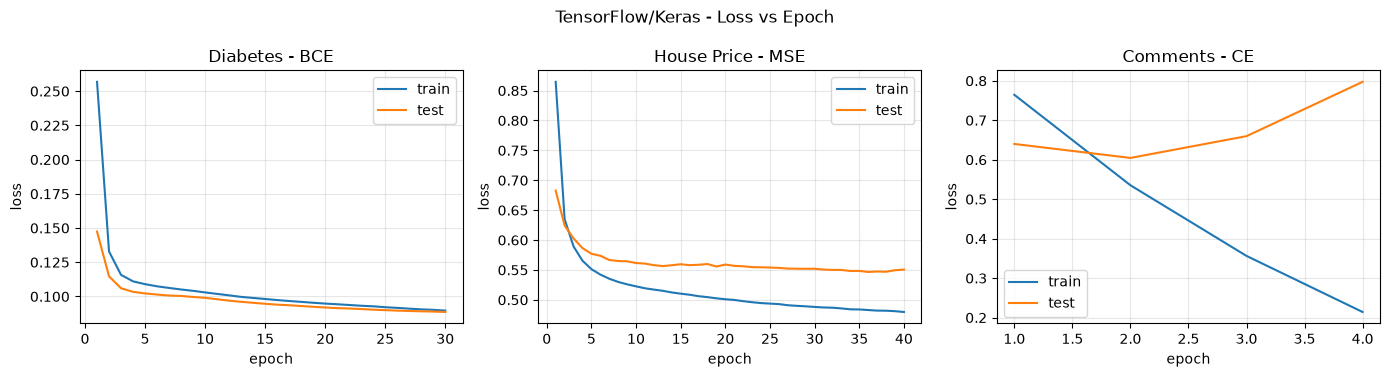

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, h, t in zip(axes, [hist_dia, hist_hou, hist_com],
                    ["Diabetes - BCE", "House Price - MSE", "Comments - CE"]):
    ax.plot(h["epoch"], h["train_loss"], label="train")
    ax.plot(h["epoch"], h["val_loss"], label="test")
    ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.set_title(t)
    ax.grid(alpha=.3); ax.legend()
fig.suptitle("TensorFlow/Keras - Loss vs Epoch")
fig.tight_layout(); plt.show()

In [10]:
L4.save_result("tensorflow", "diabetes", m_dia,
               extra=dict(history=hist_dia, n_params=int(model_dia.count_params()),
                          seconds=sec_dia, epochs=30,
                          gradienttape_accuracy=m2["accuracy"], gradienttape_f1=m2["f1"]))
L4.save_result("tensorflow", "housing",
               dict(**m_hou, mae_log=m_hou_log["mae"], r2_log=m_hou_log["r2"]),
               extra=dict(history=hist_hou, n_params=int(model_hou.count_params()),
                          seconds=sec_hou, epochs=40))
L4.save_result("tensorflow", "comments", m_com,
               extra=dict(history=hist_com, n_params=int(model_com.count_params()),
                          seconds=sec_com, epochs=EPOCHS_COM))
print("Da luu results/tensorflow_*.json")

Da luu results/tensorflow_*.json


### Nhận xét cho bản TensorFlow

1. **Ba cài đặt, một mô hình.** Kết quả trên cả ba bộ dữ liệu nằm trong cùng một
   khoảng với NumPy và PyTorch — khác biệt còn lại chỉ đến từ ngẫu nhiên
   (khởi tạo, thứ tự minibatch), không đến từ "framework nào mạnh hơn".
2. **`fit()` không phải phép màu.** Phần 3b huấn luyện đúng mô hình đó bằng
   `GradientTape` và cho kết quả tương đương; `fit()` chỉ đóng gói vòng lặp,
   callback, logging và batching.
3. **Khác biệt kỹ thuật cần chú ý:** layout `(N, L, C)` của Keras ngược với
   `(N, C, L)` của PyTorch. Nếu quên `transpose`, mô hình vẫn chạy nhưng học sai
   trục — đây là lỗi rất hay gặp khi chuyển code giữa hai framework.
4. **Chi phí khởi động.** TF mất vài giây để dựng graph/XLA trước khi chạy; với
   dữ liệu nhỏ như Diabetes, phần overhead này chiếm tỷ lệ đáng kể trong tổng thời
   gian huấn luyện.